# [기초-실습] 통계 101×데이터 분석: (1-3장): 통계분석의 기초

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/usr/share/fonts/

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 기초통계량 계산

**📘 문제**

- 온라인 쇼핑몰 고객 1,000명을 대상으로 1점부터 10점 사이의 만족도 조사를 실시했습니다.
  이 데이터를 바탕으로 고객 만족도의 **중심 경향성**과 **분포 특성**을 파악해 봅시다.

In [3]:
# 데이터 생성
np.random.seed(2025)
satisfaction = np.random.normal(7.5, 1.5, 1000)
satisfaction = np.clip(satisfaction, 1, 10)
df1 = pd.DataFrame({'score': satisfaction})

**📌 아래를 수행해 보세요:**

- 평균, 중앙값, 최빈값, 표준편차를 계산해 봅시다.
- 히스토그램을 그리고 평균과 중앙값 선으로 표시해 봅시다.
- 데이터의 분포 형태를 해석한 후, 마케팅 전략 수립에 어떻게 활용할 수 있을지 생각해 봅시다.

             score
count  1000.000000
mean      7.428690
std       1.392671
min       2.724405
25%       6.469893
50%       7.421731
75%       8.437992
max      10.000000
7.43 7.42 1.39
0    10.0
Name: score, dtype: float64
0    7.0
Name: score, dtype: float64
최빈 구간: 7.45 ~ 7.82


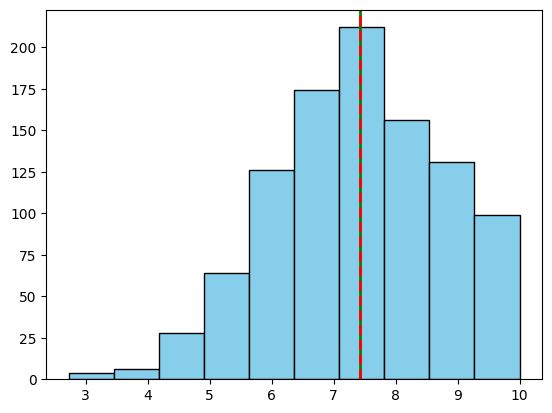

In [4]:
# 아래를 수행해 보세요:
# [문제 1] 여기에 코드를 작성해주세요.
print(df1.describe())

mean, median, std = df1["score"].agg(["mean", "median", "std"]).round(2)
mode = df1["score"].mode()
mode1 = df1["score"].round(0).mode()
print(mean, median, std)
print(mode)
print(mode1)

import numpy as np

counts, bins = np.histogram(df1["score"], bins=20)
i = counts.argmax()
print(f"최빈 구간: {bins[i]:.2f} ~ {bins[i+1]:.2f}")

import matplotlib.pyplot as plt
plt.hist(df1, bins=10, color='skyblue', edgecolor='black')
plt.axvline(median, color='green', linestyle='-', linewidth=2, label=f'Median: {median:.2f}')
plt.axvline(mean, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean:.2f}')
plt.show()


**🧠 데이터를 어떻게 읽을까요?**

1. 평균과 중앙값 사이의 차이는 어느 정도인가요?
   - 두 값이 비슷하다면, 이 데이터는 어떤 분포 형태일 가능성이 있을까요? (예: 대칭형, 정규분포 등)
   - 두 값의 차이가 크다면, 그 이유는 무엇일까요?
   - 어떤 값들이 평균을 끌어내리거나 끌어올렸을까요?

2. 최빈값이 평균보다 낮은 경우, 낮은 점수를 준 고객이 많다는 뜻일 수 있습니다. 이 경우 데이터 분포는 어느 쪽으로 치우쳐 있을까요?
   - 반대로 최빈값이 평균보다 높은 경우에는 어떤 해석이 가능할까요? 이럴 때 분포가 어떻게 달라질 수 있을까요?

3. 이 데이터를 바탕으로 고객 만족도를 높이기 위한 마케팅 전략에는 어떤 것들이 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 1] 여기에 의견을 작성해주세요.

1. 7.43 7.42로 값이 매우 비슷하여 정규분포와 유사한 종모양의 대칭형의 분포 형태일 가능성이 있다.

2. 낮은 점수를 준 고객이 많다는 뜻은 최빈값이 평균보다 작다는 뜻으로 데이터 분포는 오른쪽 꼬리 분포로 오른쪽으로 치우치게 된다. 반대의 경우에는 점수를 많이 준 고객이 많다는 뜻으로 왼쪽 꼬리 분포로 왼쪽으로 치우치게 된다.

3. 낮은 점수를 준 고객이 많다는 결과가 나온다면 점수를 높게 준 고객과 낮은 고객을 나눈 후 고객들이 낮은 점수를 준 이유를 분석하여 그 이유에 충족하는 마케팅 전략을 세울 것이다.
높은 점수를 준 고객이 많다면 이 또한 둘로 나눈 후 높은 점수를 준 고객에 대한 이탈 방지 마케팅 전략을 세울 것이다.

# 문제 2. 평균 vs 중앙값 비교

**📘 문제**

- A지역과 B지역의 연봉 데이터를 비교해 봅시다.
- B 지역에는 일부 고소득자가 포함되어 있습니다.

In [5]:
# 데이터 생성
np.random.seed(2025)

# A 지역: 평균 300, 표준편차 50
region_a = np.random.normal(300, 50, 100)

# B 지역: 일반 소득자 + 극단적인 고소득자 포함
region_b = np.concatenate([
    np.random.normal(280, 40, 95),    # 일반 소득자 95명
    np.random.normal(1500, 200, 5)    # 고소득자 5명
])

df2 = pd.DataFrame({
    'region': ['A'] * 100 + ['B'] * 100,
    'salary': np.concatenate([region_a, region_b])
})

**📌 아래를 수행해 보세요:**

- 각 지역의 평균 연봉과 중앙값을 구해 봅시다.
- 지역별 박스플롯(Boxplot)을 그려서 분포의 차이를 시각적으로 확인해 봅시다.

              mean      median
region                        
A       292.506637  294.324483
B       347.594909  287.347488


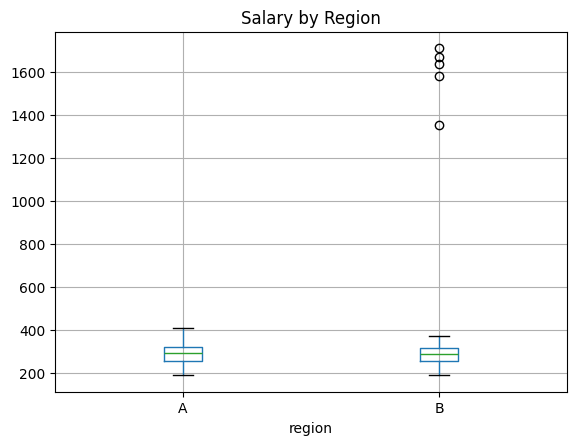

In [6]:
# 아래를 수행해 보세요:
# [문제 2] 여기에 코드를 작성해주세요.

salary = df2.groupby("region")["salary"].agg(["mean", "median"])
print(salary)

df2.boxplot(column="salary", by="region")
plt.suptitle("")          # 자동으로 붙는 큰 제목 지우기
plt.title("Salary by Region")
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. A 지역과 B 지역의 평균 연봉은 어떻게 다른가요?
   - 두 지역의 평균 차이가 의미하는 바는 무엇인가요?
   - 고소득자가 있는 지역의 평균은 어떤 영향을 받을까요?

2. 중앙값은 어떠한가요?
   - 평균과 비교했을 때, 중앙값이 더 낮거나 높다면 어떤 해석이 가능할까요?

3. 극단값(고소득자)의 영향은 어디에서 더 크게 나타날까요?
   - 평균과 중앙값 중 어떤 지표가 극단값에 더 민감한가요?

4. 박스플롯을 통해 어떤 점을 관찰할 수 있나요?
   - 이상치(Outlier)는 어떻게 표시되나요?
   - 두 지역의 분포 폭(사분위 범위)은 어떻게 다른가요?

5. 평균만 보고 판단했을 때 생길 수 있는 오해는 무엇인가요?
   - 어떤 경우에는 중앙값이 더 유용한 지표일 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 2] 여기에 의견을 작성해주세요.

1. a지역의 평균은 292.5 b지역의 평균은 327.6으로 차이가 있다. 이는 b지역에서 연봉을 높게 받는 사람이 a지역보다 많다는 것을 의미한다
 - 고소득자가 있는 지역의 평균 같은 경우 평균은 이상치에 끌려가는 성향이 있기 때문에 고소득자의 연봉으로 인해 평균이 높아진다.

2. 우선 중앙값이 평균보다 높다는 것은 왼쪽 꼬리 분포 즉 왼쪽으로 치우친 분포로 소득이 매우 적은 소수의 몇 명으로 인해 평균이 내려갔다는 것을 의미한다
반대로 중앙값이 평균보다 낮으면 오른쪽 꼬리 분포로 고소득자에 의해 평균이 높아졌다는 것을 의미한다

3. 평균이 민감하다. 중앙값은 값을 나열했을 때 중심에 오는 값이므로 이상치에 민감하지 않다

4. 박스플롯을 통해서 상위 25%, 50%, 75% 그리고 이상치를 확인할 수 있다. 이상치는 박스플롯의 바깥에 위치한 점으로 표시된다.
두 지역의 사분위 범위는 거의 같아 보이나 a지역의 50%의 기준이 더 높아보인다.

5. 박스플롯과 중앙값을 통해 확인했을 때 a지역이 b지역보다 연봉이 높은 사람이 더 많으나 b지역의 고소득자로 인해 평균값으로 구하게 되면 b지역이 더 연봉이 높다고 착각하게 된다.
    즉 이상치가 많은 경우에는 중앙값이 더 유용한 지표일 수 있다.

# 문제 3. 이상값과 분산 비교

**📘 문제**

- 1반과 2반의 시험 점수 분포를 비교해 봅시다.
- 2반에는 극단적인 이상값(예: 부정행위로 0점)이 포함되어 있습니다.

In [7]:
# 데이터 생성
np.random.seed(2025)  # 재현 가능성을 위해 시드 고정

# 1반: 평균 75, 표준편차 8
class1 = np.random.normal(75, 8, 30)

# 2반: 일반 학생 + 이상값(0점, 130점)
class2 = np.concatenate([
    np.random.normal(75, 15, 28),  # 일반 학생
    [0, 130]                       # 극단적인 이상값
])

df3 = pd.DataFrame({
    'class': ['1반'] * 30 + ['2반'] * 30,
    'score': np.concatenate([class1, class2])
})

**📌 아래를 수행해 보세요:**

1. 각 반의 평균, 표준편차, 최소/최대값을 계산해 봅시다.
2. 박스플롯을 사용하여 두 반의 분포 차이를 시각적으로 비교해 봅시다.
3. 이상값이 통계 지표에 어떤 영향을 주는지 생각해 봅시다.

            mean        std        min         max
class                                             
1반    75.724316   7.062710  60.685416   92.175893
2반    73.728848  22.340818   0.000000  130.000000


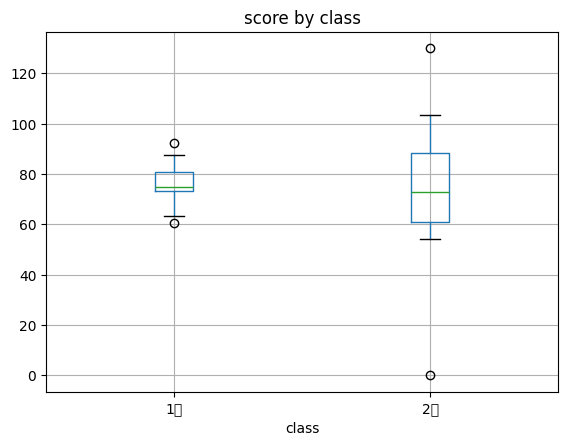

In [8]:
# 아래를 수행해 보세요:
# [문제 3] 여기에 코드를 작성해주세요.

score = df3.groupby("class")["score"].agg(["mean", "std", "min", "max"])
print(score)

df3.boxplot(column="score", by="class")
plt.suptitle("")          # 자동으로 붙는 큰 제목 지우기
plt.title("score by class")
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 어떤 반의 점수 분산이 더 크고, 왜 그럴까요?
   - 점수 분포의 퍼짐 정도는 어떤 지표로 확인할 수 있을까요?
   - 이상값이 포함되면 표준편차나 범위는 어떻게 달라질까요?

2. 이상값이 있는 반의 평균은 어떤 영향을 받았나요?
   - 극단적으로 낮거나 높은 점수가 평균을 끌어내리거나 끌어올렸나요?
   - 평균과 중앙값의 차이가 의미하는 바는 무엇인가요?

3. 박스플롯을 통해 이상값은 어떻게 드러나나요?
   - 이상값(outlier)은 박스플롯에서 어떤 형태로 나타나나요?
   - 두 반의 박스(사분위 범위)는 어떻게 다르게 보이나요?

4. 평균만 보고 평가했을 때 생길 수 있는 오해는 무엇인가요?
   - 예를 들어, 교사가 평균 점수만 보고 2반이 부족하다고 판단한다면?
   - 중앙값이나 표준편차 같은 지표와 함께 분석하는 것은 왜 중요할까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 3] 여기에 의견을 작성해주세요.
1. 2반의 점수의 분산이 훨씬 크다. 우선 점수 분포의 퍼짐 정도는 표준편차와 박스플롯의 크기를 보고 확인할 수 있다.
그리고 이상값이 포함되면 표준편차나 범위의 크기는 그로 인해 매우 커지게 된다.

2. 극단적으로 낮은 점수이 0은 평균을 끌어내리고 극단적으로 높은 점수인 130은 평균을 끌어올려서 평균이 상쇄되었지만 정확하지 못한 평균을 구하게 되었다.
박스플롯을 통해서 중앙값을 확인해봤을 때 평균과 비슷해보이지만 차이가 작다고 해서 이상값이 없다는 뜻은 아니므로 박스플롯과 표준편차를 함께 확인해야 한다.

3. 박스플롯 바깥에 점으로 표시된다. 두 반 중 a 비슷한 점수대의 학생들이 많아 사분위 범위 즉 박스의 크기가 매우 작지만  b반은 점수차이가 큰 학생들이 많아 박스의 크기가 매우 크다

4. 박스플롯을 보면 b반은 a반보다 높은 점수를 받는 학생의 수가 더 많은데 평균만 봤을 때 더 적다고 판단할 수 있다. 따라서 중앙값과 표준편차를 같이 확인하여 평균이 이상치에 의해 오염되지 않았는지 확인해야 한다.

# 문제 4. IQR 이상값 제거

**📘 문제**

- 앞의 문제에서 2반에는 **극단적인 이상값(예: 매우 낮은 점수)**이 포함되어 있어
  통계 지표, 특히 평균에 큰 영향을 주는 것을 확인했습니다.
- 이번에는 **IQR(사분위 범위)**을 기준으로 이상값을 제거한 뒤, 이상값 제거 전후의 평균을 비교해 봅시다

<br>

**📌 아래를 수행해 보세요:**

- 2반의 점수 데이터를 대상으로 IQR 기준을 사용해 이상값을 판별하고 제거해 봅시다.
- 이상값 제거 전과 제거 후의 평균을 각각 계산해 봅시다.
- 이상값 제거가 평균에 어떤 영향을 주는지 설명해 봅시다.
- 필요하다면 중앙값과도 비교해 봅시다.

In [9]:
# 아래를 수행해 보세요:
# [문제 4] 여기에 코드를 작성해주세요.

class_2 = df3[df3["class"] == "2반"]
print(class_2.head())

iqr1 = class_2["score"].quantile(0.25)
iqr3 = class_2["score"].quantile(0.75)

iqr = iqr3 - iqr1

lower = iqr1 - 1.5 * iqr
upper = iqr3 + 1.5 * iqr

class2_no = class_2[(class_2["score"] > lower) & (class_2["score"] < upper)]
print(class2_no["score"].describe())

print("제거 전:", class_2["score"].mean(), "제거 후:", class2_no["score"].mean())
print("제거 전:", class_2["score"].median(), "제거 후:", class2_no["score"].median())

   class      score
30   2반  61.486405
31   2반  56.111279
32   2반  75.849493
33   2반  60.506721
34   2반  86.228333
count     28.000000
mean      74.352338
std       14.733411
min       54.101464
25%       61.241484
50%       73.003726
75%       88.031066
max      103.523111
Name: score, dtype: float64
제거 전: 73.72884842544566 제거 후: 74.35233759869178
제거 전: 73.00372633167626 제거 후: 73.00372633167626


**🧠 데이터를 어떻게 읽을까요?**

1. 이상값 제거 전후 평균은 어떻게 달라졌나요?
   - 평균이 중앙값에 가까워졌나요?
   - 이상값 제거가 평균에 어떤 방향으로 영향을 주었나요?

2. 왜 IQR을 기준으로 이상값을 판단할까요?
   - IQR은 데이터를 어떻게 나누고, 어떤 방식으로 이상값을 정의하나요?
   - 평균이나 표준편차 기준과 비교했을 때 어떤 점이 더 강건할까요?

3. 이상값은 언제 제거하고, 언제 유지해야 할까요?
   - 분석 목적에 따라 이상값은 중요한 정보가 될 수 있습니다.

4. 중앙값과 평균은 각각 어떤 상황에서 더 유용한 지표인가요?
   - 이상값이 있을 때 어떤 지표가 더 신뢰할 수 있나요?
   - 두 지표를 함께 보면 어떤 장점이 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 4] 여기에 의견을 작성해주세요.

1. 제거 후 평균이 중앙값과 멀어졌다. 이상값 제거로 인해 기존에 점수가 높던 2반 학생들에 의해 평균이 높아져서 평균값이 바뀌었다.

2. iqr은 데이터를 크기 순으로 4등분하여 상위 25%와 75%에 가능한 범위인 iqr*1.5를 빼고 더하여 구한 값이다. 이 값보다 크거나 작은 값들은 이상값이라고 정의한다.
    평균과 표준편차는 이상값 자체의 영향을 받아 값이 커지거나 작아지기 때문에, 이상값이 있을수록 기준 범위가 넓어져 이상값을 놓칠 수 있다. 반면 IQR은 가운데 50% 데이터만으로 계산하므로 극단값의 영향을 거의 받지 않아 더 강건하다.

3. 이상값 자체가 정말 오류이거나 말이 안되는 값이 나올 때 100점인 시험에서 130점이 나오는 등 또는 분석 목적과 맞지 않을 때 그런 경우일 때는 제거하지만 
실제로 존재하는 값이면서 분석에 의미가 있는 경우(예: 부정 거래 탐지, 학습 부진 학생 파악)에는 유지해야 한다. 따라서 이상값을 무조건 지우기보다 발생 원인을 먼저 확인하고 분석 목적에 맞게 판단해야 한다.

4. 이상값이 있을 때는 이상값에 영향을 크게 받지 않는 중앙값이 더 유용한 지표이다. 그리고 두 지표를 같이 보게 되면 중앙값과 평균의 차이로 어디로 그래프가 치우쳤는지에 대한 정보를 얻을 수 있고 좀 더 신뢰성있는 도구를 택할 수 있다.

# 문제 5. 변수 유형 분류

**📘 문제**

- 아래 데이터에서 변수의 유형(연속형, 범주형, 이산형 등)을 구분해 봅시다.
- 변수의 의미를 고려하여 어떤 분석 방식이 적절한지도 함께 생각해 봅시다.

In [10]:
# 데이터 생성
np.random.seed(2025)
df5 = pd.DataFrame({
    'age': np.random.randint(18, 65, 200),
    'coffee_type': np.random.choice(['아메리카노', '라떼', '카페모카'], 200),
    'size': np.random.choice(['Small', 'Medium', 'Large'], 200),
    'price': np.random.normal(4500, 500, 200),
    'satisfaction': np.random.randint(1, 6, 200)
})

**📌 아래를 수행해 보세요:**

1. 각 변수의 데이터 타입을 확인해 봅시다.

2. 변수의 의미를 기준으로 다음 중 어떤 유형에 해당하는지 분류해 봅시다.
   - 연속형 (numeric-continuous)
   - 이산형 (numeric-discrete)
   - 범주형 (categorical)
   - 서열형 범주 (ordinal-categorical)

In [11]:
# 아래를 수행해 보세요:
# [문제 5] 여기에 코드를 작성해주세요.
print(df5.head())

print(df5.dtypes)

   age coffee_type    size        price  satisfaction
0   48    카페모카   Small  4435.448359             1
1   36        라떼   Small  4849.195869             4
2   48    카페모카   Large  4365.135391             1
3   30  아메리카노  Medium  3979.605848             2
4   21    카페모카   Small  4650.242695             1
age               int64
coffee_type      object
size             object
price           float64
satisfaction      int64
dtype: object


**🧠 데이터를 어떻게 읽을까요?**

1. 숫자처럼 보이지만 사실은 범주형 또는 서열형으로 해석하는 변수가 있다면 무엇일까요?

2. 변수 유형에 따라 적절한 분석 방법이나 시각화 방식은 어떻게 달라질까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 5] 여기에 의견을 작성해주세요.
1. 만족도 같은 변수이다. 정해져있는 목록 상에서 정하는 변수이고 더하고 뺄 수 없는 변수이지만 뭐가 더 크다는 것은 알 수 있는 변수이기 때문에

2. 범주형의 경우에는 각각의 빈도나 비율을 활용해서 막대그래프나 히스토그램으로 시각화해야하지만 수치형의 경우 기술통계를 활용할 수 있고 박스플롯이나 히스토그램을 활용하여 분포를 확인한다.

# 문제 6. 상관관계 분석

**📘 문제**

- 이번에는 변수들 간의 **관계(상관관계)**를 분석해 봅시다.
- 특히 기온(`temp`), 습도(`humidity`), 판매(`sales`) 변수 간의 관계를 수치와 시각화로 살펴보겠습니다.

In [12]:
# 데이터 생성
np.random.seed(202)

temp = np.random.normal(25, 5, 100)
humidity = np.random.normal(60, 10, 100)
sales = temp * 10 - humidity * 2 + np.random.normal(0, 20, 100) + 200

df6 = pd.DataFrame({'temp': temp, 'humidity': humidity, 'sales': sales})

**📌 아래를 수행해 보세요:**

1. 아래의 기온, 습도, 매출 데이터를 사용하여 상관계수 행렬을 출력해 봅시다.

2. 페어플롯(pairplot)을 이용하여 변수 간의 관계를 시각화해 봅시다.

          temp  humidity  sales
temp      1.00     -0.12   0.91
humidity -0.12      1.00  -0.39
sales     0.91     -0.39   1.00


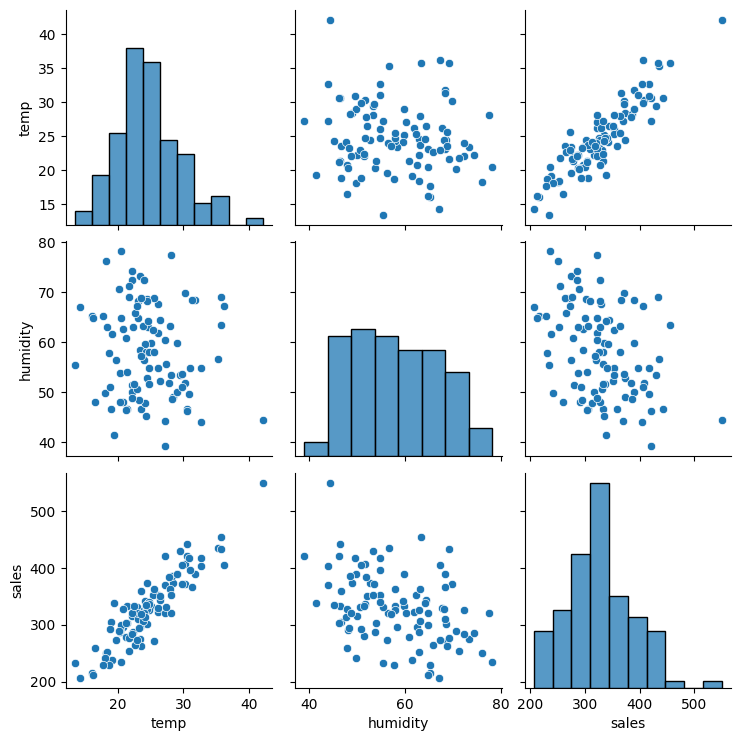

In [13]:
# 아래를 수행해 보세요:
# [문제 6] 여기에 코드를 작성해주세요.
import seaborn as sns

corr = df6.corr().round(2)
print(corr)


sns.pairplot(df6)
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 출력된 상관계수 행렬을 보고,
   - 어떤 변수와 `sales` 간의 상관계수가 가장 높은가요?
   - 어느 쌍이 **양의 상관관계**, 어느 쌍이 **음의 상관관계**인가요?

2. 페어플롯에서
   - 어떤 변수 쌍은 **직선 형태**로 관계가 보이나요?
   - 어떤 변수 쌍은 **분산이 크거나 패턴이 없는**가요?

3. **상관관계가 반드시 인과관계를 의미하지는 않습니다.**
   - 온도와 매출에 상관관계가 있다고 해서, 온도가 매출을 직접적으로 증가시킨다고 볼 수 있을까요?

4. 이 데이터를 바탕으로 어떤 **추가 가설**이나 **실험 설계**를 생각해볼 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 6] 여기에 의견을 작성해주세요.
1. temp 기온과 sales간의 상관계수가 0.91로 가장 높다.
    temp - sales = 양의 상관관계 / temp - humidity = sales - humidity = 음의 상관관계
2. temp 와 sales의 변수 쌍은 직선의 형태로 관계가 보이나 temp - humidity은 분산이 매우 크고 패턴이 거의 없다 sales와 humidity는 약한 음의 경향이 보이나 흩어짐이 커서 관계가 약하다.

3. 온도가 매출에 영향을 미칠 수 있다는 거지만 온도가 높다고 해서 무조건 매출이 높다고 볼 수 없는 등 확실한 원인이 아니기 때문에 인과관계를 의미하지 않는다.

4. 가설 : 다른 조건이 같아도 기온이 오르면 매출이 증가할 것이다. → 요일·휴일·프로모션 여부 데이터를 추가로 수집해 조건이 같은 날끼리 비교하거나, 이 변수들을 함께 넣은 회귀분석으로 기온의 효과가 남는지 확인한다.

# 문제 7. 범주형 변수 시각화

**📘 문제**

- 앞에서는 수치형 변수의 분포를 시각화하고, 변수 간의 관계도 살펴보았습니다.
- 이번에는 범주형 변수인 커피 음료 데이터를 시각화해 봅시다.
- 어떤 종류가 많이 판매되었는지 빈도 분석을 통해 알아보겠습니다.

In [14]:
# 데이터 생성
df7 = pd.DataFrame({
    'drink': np.random.choice(['아메리카노', '라떼', '콜드브루'], 300)
})

**📌 아래를 수행해 보세요:**

1. 아래 데이터에서 drink 변수는 판매된 음료의 종류를 나타냅니다.
   - 각각 몇 개씩 판매되었는지 빈도표를 만들어 확인해 봅시다.
   - **막대그래프(bar plot)**를 그려서 결과를 시각화해 봅시다.

2. 시각화 결과를 보고,
   - 어떤 음료가 가장 많이 팔렸는지 파악해 봅시다.
   - 이 결과를 마케팅 전략에 어떻게 활용할 수 있을지 생각해 봅시다.

drink
콜드브루      108
아메리카노     97
라떼           95
Name: count, dtype: int64


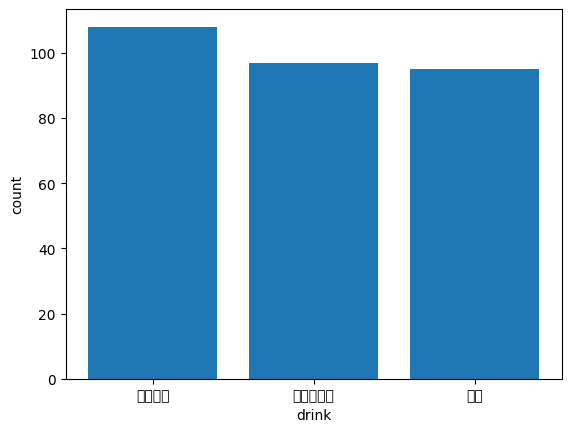

In [15]:
# 아래를 수행해 보세요:
# [문제 7] 여기에 코드를 작성해주세요.
counts = df7["drink"].value_counts()
print(counts)

plt.bar(counts.index, counts.values)
plt.xlabel("drink")
plt.ylabel("count")
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 출력된 빈도표와 막대그래프를 보면, 어떤 음료가 가장 많이 판매되었나요?
   - 판매량이 가장 많은 음료는?
   - 그 다음으로 인기 있는 음료는?

2. 이 결과는 어떤 마케팅 전략에 활용할 수 있을까요?
   - 가장 많이 팔린 음료를 주력 상품으로 홍보해야 할까요?
   - 판매량이 적은 음료를 프로모션 대상으로 삼는 것은 어떨까요?

3. 막대그래프는 왜 범주형 변수에 적합할까요?
   - `drink`처럼 종류가 명확히 나뉘는 변수를 분석할 때 어떤 점이 중요한가요?

4. 범주형 변수 분석 시 주의할 점은?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 7] 여기에 의견을 작성해주세요.
1. 콜드브루 / 아메리카노

2. 우선 인기 음료를 메인으로 홍보를 한다. 그리고 판매량이 적은 음료는 왜 적은 지에 대한 파악을 한 후 맛이 문제였거나 인지도 문제였는지에 따라 시음회를 하거나 프로모션, 또는 레시피를 바꾸는 등의 전략을 시행한다.

3. 범주형 변수의 경우 각 값이 서로 구분되는 종류이므로 막대그래프로 서로의 빈도를 비교하는 것이 적합하다
drink처럼 종류가 명확히 나뉘는 변수는 평균이나 표준편차를 구할 수 없으므로, 각 범주의 빈도와 비율을 비교하는 것이 중요하다.

4. 표기 통일, 결측치, 숫자로 된 범주형 변수 주의, 빈도와 비율 확인(각그룹의 크기가 다르면 빈도로는 비교가 힘듦)

# 문제 8. 요일별 평균 비교

**📘 문제**

- 이번에는 요일 별 소비 금액 데이터를 분석해 봅시다.
- 각 요일마다 평균 소비 금액이 얼마나 되는지 비교하고,
  **평일과 주말의 소비 패턴 차이**도 함께 살펴보겠습니다.

In [16]:
# 데이터 생성
df8 = pd.DataFrame({
    'day': np.random.choice(['월', '화', '수', '목', '금', '토', '일'], 500),
    'amount': np.random.normal(12000, 2000, 500)
})

**📌 아래를 수행해 보세요:**

1. 아래 데이터를 사용하여 `day`(요일)별 `amount`(소비 금액)의 평균을 계산해 봅시다.
2. 요일별 평균 금액을 **막대그래프(bar plot)**로 시각화해 봅시다.

  day        amount
0  수  11664.504203
1  월  15098.406430
2  수  10692.619664
3  일  11032.459859
4  화  14512.894344
day
수    12232.99
토    12188.06
목    11983.72
화    11762.88
금    11749.98
월    11709.24
일    11502.62
Name: amount, dtype: float64
11900.0 11854.86


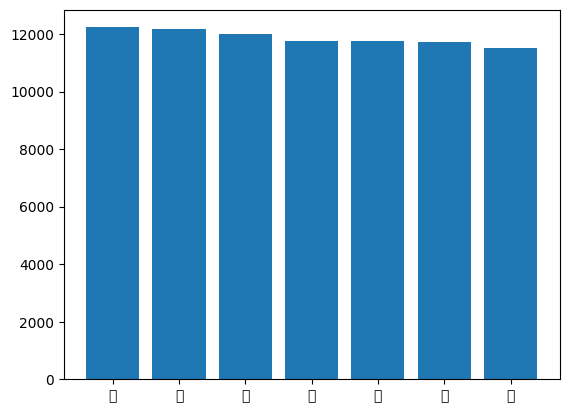

In [17]:
# 아래를 수행해 보세요:
# [문제 8] 여기에 코드를 작성해주세요.
print(df8.head())
day_amount = df8.groupby("day")["amount"].mean().round(2).sort_values(ascending=False)
print(day_amount)

plt.bar(day_amount.index, day_amount.values)

day_w = df8[df8["day"].isin(['월', '화', '수', '목', '금'])]["amount"].mean().round(2)
day_we = df8[df8["day"].isin(['토', '일'])]["amount"].mean().round(2)
print(day_w, day_we)

**🧠 데이터를 어떻게 읽을까요?**

1. 어떤 요일에 소비 금액이 가장 높나요?
   - 주말(토, 일)과 평일(월~금) 중 어떤 쪽의 평균이 더 높은가요?

2. 소비 금액이 적은 요일은 언제인가요? 왜 그럴까요?

3. 이 결과를 어떻게 활용할 수 있을까요?
   - 주말에 더 많은 재고를 준비하거나
   - 평일에 할인 이벤트를 기획하는 등의 운영/마케팅 전략으로 이어질 수 있을까요?

---

> 💬 정리해 보기
>
> - 범주형 변수(요일)별로 연속형 변수(소비 금액)의 평균을 비교하면 소비 패턴을 이해하고 전략을 수립하는 데 유용한 인사이트를 얻을 수 있습니다.

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 8] 여기에 의견을 작성해주세요.
1. 수요일에 소비 금액이 가장 높았고 평일의 평균이 크게 차이는 나지 않지만 조금 더 높았

2. 일요일의 소비 금액이 적었다. 일요일에는 간단한 소액 구매가 많거나, 인기 고가 상품의 재고가 부족했거나, 휴일이라 외출·쇼핑 패턴이 평일과 달랐을 가능성이 있다. 다만 가장 높은 수요일과의 차이가 약 730원(약 6%)으로 크지 않아, 우연에 의한 차이인지 추가 확인이 필요하다.

3. 일요일의 평균 소비 금액이 가장 낮으므로, 재고 부족이 원인이라면 일요일 전에 고가 인기 상품의 재고를 충분히 확보할 수 있다. 또한 일요일에는 묶음 할인이나 일정 금액 이상 구매 시 혜택을 주는 이벤트를 진행해 소비 금액을 높이는 전략을 세울 수 있다. 
    반대로 소비 금액이 높은 수요일과 토요일에는 고가 상품을 중심으로 진열·홍보해 매출을 더 끌어올릴 수 있다. 다만 요일 간 차이가 크지 않으므로, 이벤트 전후의 매출을 비교해 실제 효과를 확인하는 것이 좋다.

# 문제 9. 정규분포와 표준편차

**📘 문제**

- 정규분포와 표준편차의 개념을 실제 데이터에 적용해 보겠습니다.
- 정규분포를 따르는 점수 데이터에서 다음을 확인해 봅시다:
  - 평균 ±1σ, 평균 ±2σ 범위에 속한 값들의 비율은 실제로 얼마나 되는가?
  - 이 결과가 이론적인 68-95-99 법칙과 얼마나 유사한지 비교해 봅시다.

<br>

**📌 아래를 수행해 보세요:**

1. 평균이 70, 표준편차가 10인 정규분포 데이터를 1000개 생성해 봅시다.
2. 평균을 중심으로 ±1σ, ±2σ 범위에 포함되는 데이터의 비율을 계산해 봅시다.
3. 결과를 바탕으로 68-95-99 법칙과 비교해 봅시다.

In [18]:
# 아래를 수행해 보세요:
# [문제 9] 여기에 코드를 작성해주세요.
np.random.seed(42)
df9 = np.random.normal(70, 10, 1000)

mean = df9.mean()
std = df9.std()
print(mean, std)
Q1 =((df9 > (mean - std)) & (df9 < (mean + std))).sum()
print(Q1 / 1000 * 100)
Q2 =((df9 > (mean - std * 2)) & (df9 < (mean + std * 2))).sum()
print(Q2 / 1000 * 100)

70.19332055822326 9.787262077473542
68.60000000000001
95.6


**🧠 데이터를 어떻게 읽을까요?**

1. ±1σ, ±2σ 범위에 실제로 몇 %의 데이터가 포함되었나요?
2. 이 결과는 68–95–99 법칙과 얼마나 비슷했나요?
3. 표준편차는 왜 중요한 지표인가요?
4. 이 개념이 실제로 어떻게 활용될 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 9] 여기에 의견을 작성해주세요.

1. 약 68.6%, 약 95.6%

2. 0.6%정도만 차이나고 거의 비슷했다

3. 표준편차는 평균만으로는 알 수 없는 데이터의 퍼짐 정도를 보여 주며, 평균이 같아도 표준편차가 크면 값들이 넓게 흩어져 있어 평균의 대표성이 낮아지기 때문에 중요하다.

4. 시험 점수에서 평균 ±2σ를 벗어난 학생을 찾아 보충 지도를 하거나, 공장에서 제품 무게가 ±3σ를 벗어나면 불량으로 판정하는 등 이상값 탐지와 품질 관리에 활용할 수 있다. 

# 문제 10. 표본 평균 실험

**📘 문제**

- 큰 모집단에서 표본을 여러 번 추출하여 표본 평균의 분포를 비교해봅시다.

<br>

**📌 아래를 수행해 보세요:**

1. 평균이 100, 표준편차가 15인 모집단을 생성합니다.
2. 다음 두 조건에서 각각 1000번씩 표본 평균을 구합니다:
   - 표본 크기 5
   - 표본 크기 50
3. 두 조건의 **표본 평균 분포(histogram)**를 비교합니다.

n=5  평균: 100.11  표준편차: 6.57
n=50 평균: 100.15  표준편차: 2.09


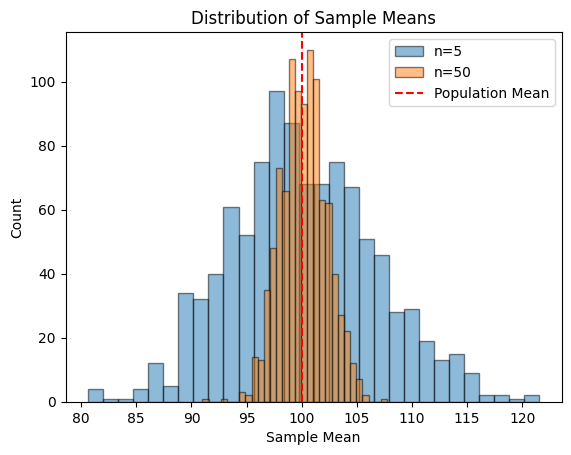

In [19]:
# 아래를 수행해 보세요:
# [문제 10] 여기에 코드를 작성해주세요.
import numpy as np
import matplotlib.pyplot as plt


np.random.seed(42)
df10 = np.random.normal(100, 15, 100000)

# 2. 표본 평균 1000번씩 구하기
means_5 = []
means_50 = []

for i in range(1000):
    sample_5 = np.random.choice(df10, size=5)
    sample_50 = np.random.choice(df10, size=50)
    means_5.append(sample_5.mean())
    means_50.append(sample_50.mean())

# 3. 히스토그램 비교
plt.hist(means_5, bins=30, alpha=0.5, label='n=5', edgecolor='black')
plt.hist(means_50, bins=30, alpha=0.5, label='n=50', edgecolor='black')
plt.axvline(100, color='red', linestyle='--', label='Population Mean')
plt.title('Distribution of Sample Means')
plt.xlabel('Sample Mean')
plt.ylabel('Count')
plt.legend()
plt.show()

# 숫자로 비교
print("n=5  평균:", round(np.mean(means_5), 2), " 표준편차:", round(np.std(means_5), 2))
print("n=50 평균:", round(np.mean(means_50), 2), " 표준편차:", round(np.std(means_50), 2))

**🧠 데이터를 어떻게 읽을까요?**

1. **표본 크기가 다를 때 표본 평균 분포는 어떻게 달라졌나요?**
2. **왜 표본 크기가 중요할까요?**
3. **이 개념은 실제로 어디에 활용될 수 있을까요?**

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 10] 여기에 의견을 작성해주세요.

1. 두 조건 모두 표본 평균이 모집단 평균(100)과 비슷했지만, 표본 평균의 표준편차는 표본 크기 5일 때 6.57, 50일 때 2.09로 표본 크기가 클수록 분포가 좁고 뾰족해졌다.

2. 표본 크기가 클수록 표본 평균이 모집단 평균 가까이 모여 우연에 의한 오차가 줄어든다. 따라서 표본 하나만으로도 모집단을 더 정확하게 추정할 수 있기 때문이다.

3. 여론조사에서 응답자 수를 정하거나, 공장에서 일부 제품만 검사해 전체 품질을 판단하거나, 신약 임상시험에서 필요한 참가자 수를 정할 때 활용된다.

# 문제 11. 단순 선형 회귀 분석

**📘 문제**

- 공부 시간과 성적 간의 관계를 회귀 분석으로 확인해봅시다.

In [20]:
# 데이터 생성
import pandas as pd
from sklearn.linear_model import LinearRegression

np.random.seed(505)
study_time = np.random.normal(5, 2, 100)
score = 50 + study_time * 8 + np.random.normal(0, 5, 100)
df11 = pd.DataFrame({'study_time': study_time, 'score': score})

**📌 아래를 수행해 보세요:**

1. 공부 시간(`study_time`)과 성적(`score`)간의 관계를 단순 선형 회귀모델로 분석합니다.
2. 회귀 모델을 학습하고, 기울기(계수)와 절편을 출력해 봅시다.
3. 산점도 위에 회귀선을 시각화해 봅시다.

기울기(계수): 7.91
절편: 51.61
결정계수(R²): 0.93


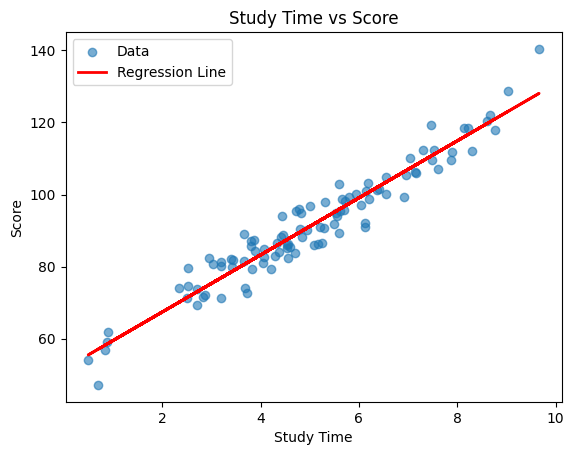

In [21]:
# 아래를 수행해 보세요:
# [문제 11] 여기에 코드를 작성해주세요.
# 1. 데이터 준비 (df는 실제 데이터프레임 이름으로 바꿔 주세요)
X = df11[["study_time"]]   # 독립변수: 대괄호 2개 (2차원 형태)
y = df11["score"]          # 종속변수: 대괄호 1개

# 2. 모델 학습 + 기울기·절편 출력
model = LinearRegression()
model.fit(X, y)

print("기울기(계수):", round(model.coef_[0], 2))
print("절편:", round(model.intercept_, 2))
print("결정계수(R²):", round(model.score(X, y), 2))

# 3. 산점도 + 회귀선
y_pred = model.predict(X)

plt.scatter(df11["study_time"], y, alpha=0.6, label="Data")
plt.plot(df11["study_time"], y_pred, color="red", linewidth=2, label="Regression Line")
plt.title("Study Time vs Score")
plt.xlabel("Study Time")
plt.ylabel("Score")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

1. 공부 시간이 성적에 어떤 영향을 주었나요?
2. 회귀선은 데이터를 잘 설명하고 있나요?
3. 이 회귀식을 현실에 적용할 수 있을까요?
4. 선형 회귀분석은 언제 활용할 수 있을까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 11] 여기에 의견을 작성해주세요.
1. 회귀식은 score = 7.91 × study_time + 51.61이며, 공부 시간이 1시간 늘어날 때마다 성적이 평균적으로 약 7.91점 높아지는 양의 관계를 보였다.

2. 산점도에서 점들이 회귀선 주변에 가깝게 모여 있고, 결정계수(R²)도 1에 가까운 0.93이 나와 회귀선이 데이터를 잘 설명하고 있다.

3. 데이터 범위 안에서 성적을 예측하는 데는 활용할 수 있다. 하지만 공부 시간을 7시간으로 넣으면 약 107점처럼 만점을 넘는 값이 나오는 등 범위를 벗어나면 맞지 않다. 또한 회귀분석은 관계를 보여 줄 뿐이라, 공부 습관·이해력 같은 다른 요인이 있을 수 있으므로 공부 시간이 성적의 직접적인 원인이라고 단정하기는 어렵다.

4. 광고비에 따른 매출 예측, 기온에 따른 음료 판매량 예측, 면적에 따른 집값 예측처럼 한 변수로 다른 수치형 변수를 예측하거나, 두 변수 사이의 관계 크기를 수치로 확인하고 싶을 때 활용할 수 있다.


# 문제 12. A/B 테스트 해석

**📘 문제**

- 두 그룹의 전환율 차이를 계산하고 해석해봅시다.

In [22]:
# 데이터 생성
np.random.seed(606)
group_a = np.random.binomial(1, 0.12, 1000)
group_b = np.random.binomial(1, 0.15, 1000)

**📌 아래를 수행해 보세요:**

1. A 그룹과 B 그룹의 전환 데이터를 살펴봅니다.
2. 각 그룹의 전환율을 계산하고, 차이를 확인합니다.
3. 이 차이가 우연인지, 의미 있는 차이인지 생각해 봅시다.

In [23]:
# 아래를 수행해 보세요:
# [문제 12] 여기에 코드를 작성해주세요.
import numpy as np
from scipy import stats

# 1. 데이터 살펴보기
print("A 그룹 인원:", len(group_a), " 전환 수:", np.sum(group_a))
print("B 그룹 인원:", len(group_b), " 전환 수:", np.sum(group_b))

# 2. 전환율 계산 + 차이 확인
rate_a = np.mean(group_a)
rate_b = np.mean(group_b)

print(f"A 전환율: {rate_a:.2%}")
print(f"B 전환율: {rate_b:.2%}")
print(f"차이(B - A): {rate_b - rate_a:.2%}")



A 그룹 인원: 1000  전환 수: 131
B 그룹 인원: 1000  전환 수: 133
A 전환율: 13.10%
B 전환율: 13.30%
차이(B - A): 0.20%


**🧠 데이터를 어떻게 읽을까요?**

1. 두 그룹의 전환율 차이는 얼마나 되나요?
2. 차이가 '의미 있다'는 건 무엇을 뜻하나요?
3. 이 실험 결과로 어떤 결정을 내릴 수 있을까요?
4. A/B 테스트는 현실에서 어떻게 쓰일까요?

In [ ]:
# 데이터를 어떻게 읽을까요?
# [문제 12] 여기에 의견을 작성해주세요.

1. 0.2%로 b그룹이 약간 더 높다

2. 차이가 의미 있다는 것은 그 차이가 표본을 뽑을 때 발생하는 우연한 값이 아니라 두 그룹 사이에 실제로 다르다는 뜻이다.

3. 두 그룹의 전환율 차이가 0.2%p로 매우 작아 우연히 생긴 차이일 수 있으므로, 이 결과만으로 B가 더 낫다고 결정하기는 어렵다. 따라서 바로 B로 바꾸기보다는 더 많은 사람을 대상으로 다시 실험해 확인하는 것이 좋다.

4. 웹사이트의 버튼 색이나 광고 문구, 이메일 제목 등을 두 가지로 만들어 사람들에게 무작위로 나눠 보여 준 뒤, 클릭이나 구매가 더 많이 일어난 쪽을 선택하는 데 쓰인다.